# Proyecto del 1er Parcial  — Predicción del rendimiento académico con aprendizaje automático

| | |
|---|---|
| **Integrantes** | JORDAN EDUARDO CHANCAY REYES · ERICK RICARDO MUÑIZ RUIZ · DAVID ALEXANDER PAREDES FLORES · SAUL HUMBERTO ZAMBRANO CEDEÑO |
| **Paralelo** | CDDEIA-ELMA-4-1|
| **Grupo** | B |
| **Fecha** | 25 de noviembre de 2026|
| **Asignatura** | APRENDIZAJE AUTOMÁTICO|
| **Docente** | ING. DARWIN ALEXA RODRIGUEZ MERCHÁN MSc|
| | |

## Contexto y objetivo

Una institución educativa quiere identificar a tiempo a los estudiantes en riesgo de reprobar para ofrecerles tutorías. Construimos un pipeline completo sobre el dataset *Student Performance / Student Alcohol Consumption* (Cortez & Silva, 2008). De los dos archivos disponibles (Matemática y Portugués, con las mismas 33 variables) trabajamos únicamente con `student-por.csv` (Portugués). Con él buscamos responder dos preguntas:

1. **Regresión lineal:** ¿qué nota final (`G3`) obtendrá un estudiante?
2. **Regresión logística:** ¿aprobará (`G3 ≥ 10`) o reprobará?

# Parte 1. Análisis exploratorio de datos (EDA)

## 1.1 Carga y estructura del dataset

In [2]:
# ============================================================
# Librerías y configuración general
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sns.set(color_codes=True)
pd.set_option("display.max_columns", 50)

In [3]:
# 1.1 Carga del dataset de Portugués
import kagglehub
from kagglehub import KaggleDatasetAdapter

df_por = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, "uciml/student-alcohol-consumption", "student-por.csv")

df_por.head()

C:\Users\FamiliaPF\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [4]:
# 1.1 Estructura: filas y columnas
print("Filas:", df_por.shape[0])
print("Columnas:", df_por.shape[1])

Filas: 649
Columnas: 33


In [5]:
# 1.1 Tipos de variables y valores no nulos
df_por.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [6]:
# 1.1 Valores nulos en total
print("Valores Nulos totales:", df_por.isnull().sum().sum())

Valores Nulos totales: 0


In [7]:
# 1.1 Estadísticas descriptivas de las variables numéricas
print("----------------Estadísticas Descriptivas ----------------")
df_por.describe().T.round(2)

----------------Estadísticas Descriptivas ----------------


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


In [8]:
# 1.1 Estadísticas descriptivas de las variables categóricas
print("------Estadísticas Descriptivas--------")
df_por.select_dtypes(exclude="number").describe().T

------Estadísticas Descriptivas--------


,count,unique,top,freq
school,649,2,GP,423
sex,649,2,F,383
address,649,2,U,452
famsize,649,2,GT3,457
Pstatus,649,2,T,569
Mjob,649,5,other,258
Fjob,649,5,other,367
reason,649,4,course,285
guardian,649,3,mother,455
schoolsup,649,2,no,581


### **Interpretación de 1.1**

**Estructura.** El archivo de Portugués contiene 649 estudiantes y 33 columnas: 16 variables numéricas enteras, como edad, educación de los padres, escalas de 1 a 5, ausencias y notas G1, G2 y G3; y 17 variables categóricas, como escuela, sexo, trabajo de los padres y apoyo escolar. No hay valores nulos. 

**Nota final G3.** La media es 11,91, la desviación estándar 3,23 y la mediana 12, con valores entre 0 y 19. La mayoría supera la nota de aprobación de 10 y las calificaciones presentan una dispersión relativamente baja.

**Ausencias.** La mediana es 2, la media 3,66 y el máximo 32. La diferencia entre la media y la mediana indica que algunos estudiantes acumulan muchas ausencias.

**Otras variables.** Las variables ordinales famrel, freetime, goout, Dalc y health utilizan escalas de 1 a 5. En Dalc, que representa el consumo de alcohol entre semana, la mediana es 1, lo que refleja un consumo bajo en la mayoría. Entre las variables categóricas, predominan los estudiantes de la escuela GP, de zonas urbanas y que desean continuar estudios superiores, con 580 de 649 estudiantes. Por tanto, pocos estudiantes no planean seguir estudiando.

## 1.2 Distribuciones

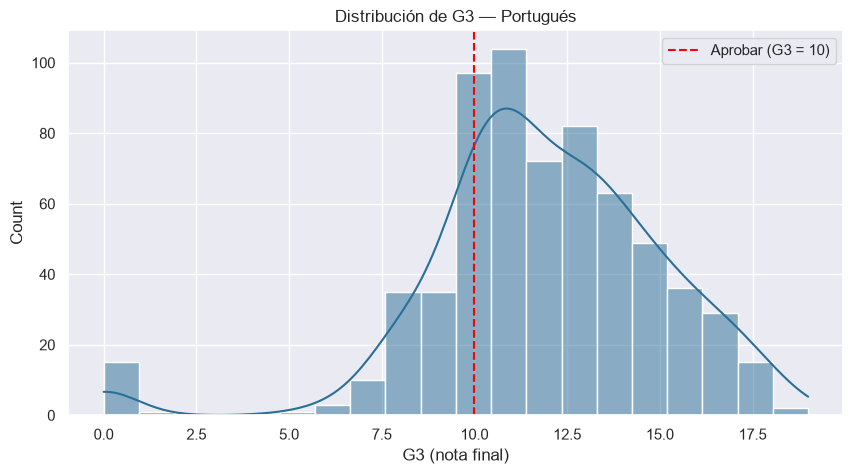

In [9]:
# 1.2 Distribución de G3
plt.figure(figsize=(10, 5))
sns.histplot(df_por["G3"], bins=20, kde=True, color="#2a6f97")
plt.axvline(10, color="red", ls="--", label="Aprobar (G3 = 10)")
plt.title("Distribución de G3 — Portugués")
plt.xlabel("G3 (nota final)")
plt.legend()
plt.show()

In [10]:
# 1.2 Frecuencia de cada nota final G3
print(df_por["G3"].value_counts().sort_index().to_string())

G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19      2


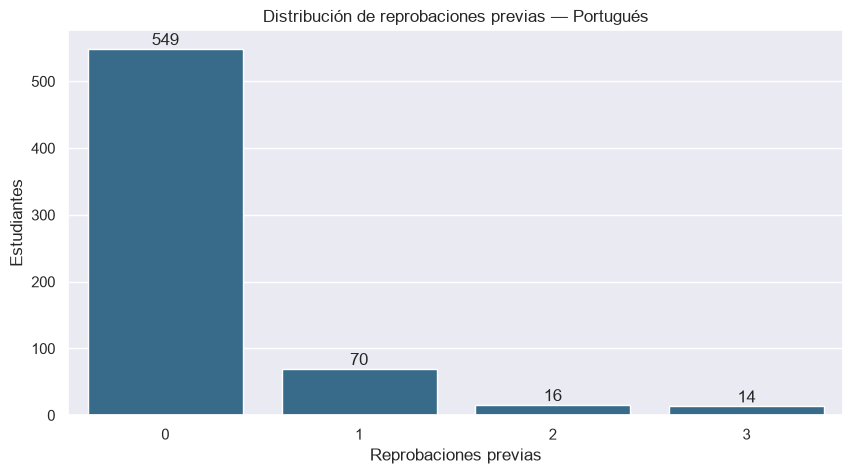

In [50]:
# 1.2 Distribución de reprobaciones previas
plt.figure(figsize=(10, 5))
ax = sns.countplot(x="failures", data=df_por, color="#2a6f97")
ax.bar_label(ax.containers[0])
plt.title("Distribución de reprobaciones previas — Portugués")
plt.xlabel("Reprobaciones previas")
plt.ylabel("Estudiantes")
plt.show()

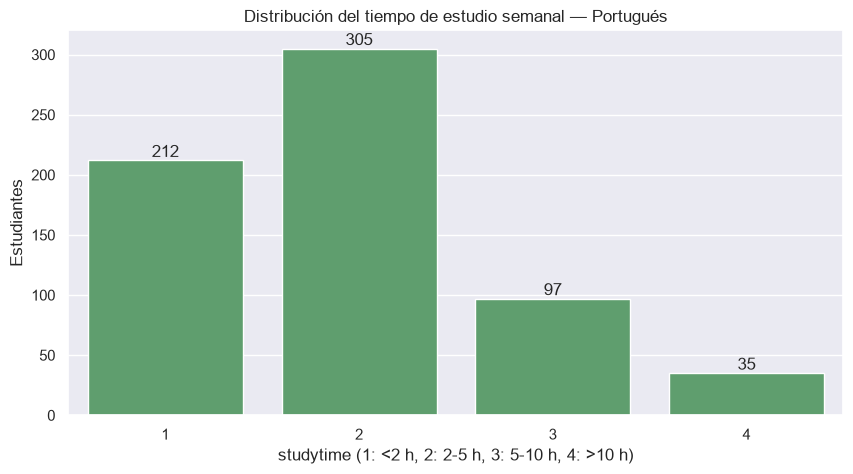

In [ ]:
# 1.2 Distribución del tiempo de estudio semanal
plt.figure(figsize=(10, 5))
ax = sns.countplot(x="studytime", data=df_por, color="#55a868")
ax.bar_label(ax.containers[0])
plt.title("Distribución del tiempo de estudio semanal — Portugués")
plt.xlabel("studytime (1: <2 h, 2: 2-5 h, 3: 5-10 h, 4: >10 h)")
plt.ylabel("Estudiantes")
plt.show()

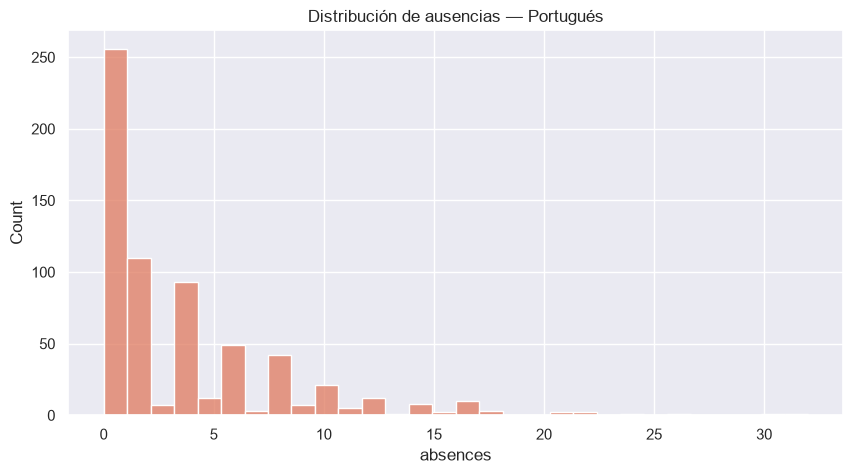

In [13]:
# 1.2 Distribución de ausencias 
plt.figure(figsize=(10, 5))
sns.histplot(df_por["absences"], bins=30, color="#e07a5f")
plt.title("Distribución de ausencias — Portugués")
plt.show()

In [14]:
# 1.2 Estudiantes con G3 = 0
n0 = (df_por["G3"] == 0).sum()
print("Estudiantes con G3 = 0:", n0, "(", round(n0 / len(df_por) * 100, 1), "%)")

Estudiantes con G3 = 0: 15 ( 2.3 %)


#### **Interpretación de 1.2**

**Distribución de G3.** Las notas finales presentan una ligera asimetría hacia la izquierda. Se observa que 15 estudiantes obtuvieron una calificación de cero, mientras que casi no existen notas entre 1 y 5, posiblemente por abandono o inasistencia a las evaluaciones. La mayoría de los estudiantes aprueba, concentrando sus calificaciones entre 10 y 14 puntos, con mayor frecuencia en 11.

**Reprobaciones previas.** La mayoría de los estudiantes no registra reprobaciones anteriores, con 549 casos. Solo 70 han reprobado una vez, mientras que los casos de dos y tres reprobaciones son mucho menos frecuentes, con 16 y 14 estudiantes.

**Tiempo de estudio.** La mayoría de los estudiantes dedica entre 2 y 5 horas semanales al estudio, seguida de quienes estudian menos de 2 horas. En cambio, pocos alumnos superan las 5 horas de estudio a la semana, lo que refleja una baja dedicación al estudio intensivo.

**Ausencias.** La mayoría de los estudiantes presenta pocas inasistencias, principalmente entre 0 y 2 faltas. Sin embargo, existen casos que alcanzan las 32 ausencias, lo que genera una distribución asimétrica hacia la derecha. Por ello, es importante revisar los valores extremos antes de aplicar modelos predictivos.

## 1.3 Correlaciones

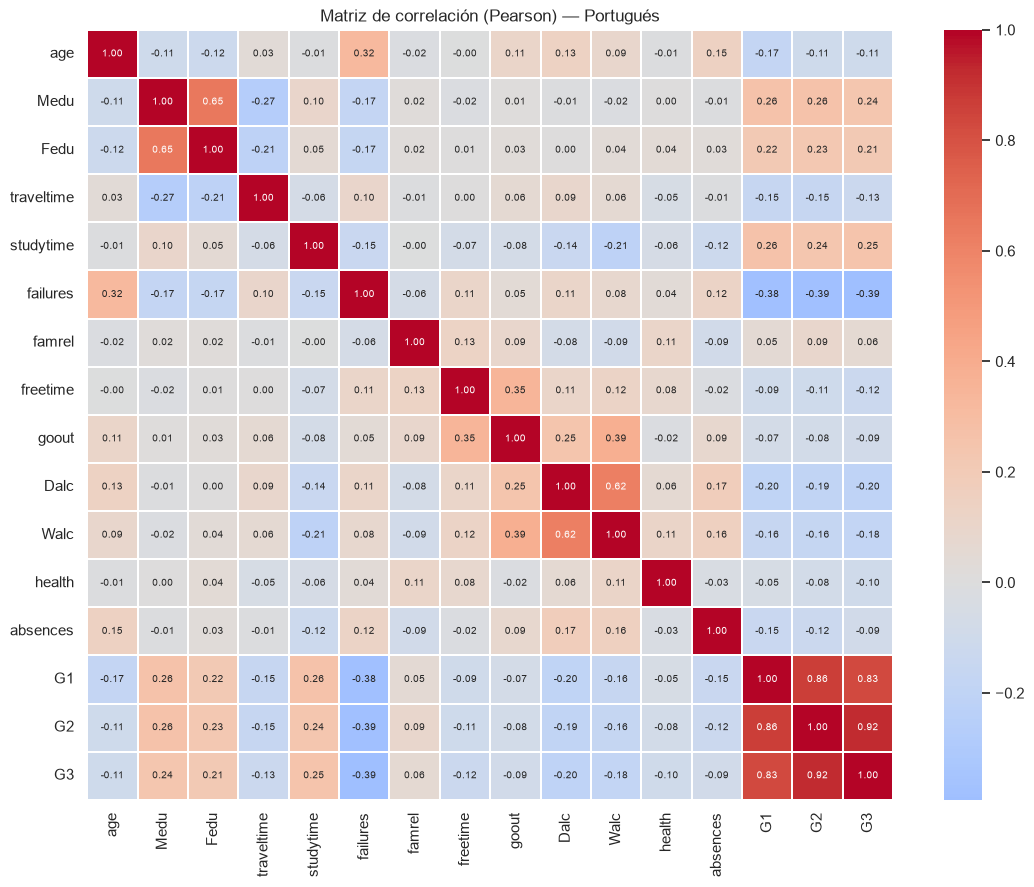

In [15]:
# 1.3 Matriz de correlación (Pearson) de las variables numéricas
plt.figure(figsize=(13, 10))
corr = df_por.select_dtypes(include="number").corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.3)
plt.title("Matriz de correlación (Pearson) — Portugués")
plt.show()

In [16]:
# 1.3 Variables más relacionadas con G3 (ordenadas por valor absoluto)
corr["G3"].drop("G3").sort_values(key=abs, ascending=False).round(3)

G2            0.919
G1            0.826
failures     -0.393
studytime     0.250
Medu          0.240
Fedu          0.212
Dalc         -0.205
Walc         -0.177
traveltime   -0.127
freetime     -0.123
age          -0.107
health       -0.099
absences     -0.091
goout        -0.088
famrel        0.063
Name: G3, dtype: float64

### **Interpretación de 1.3**

**Variables más relacionadas con G3.** Las notas anteriores son las que presentan mayor relación con la nota final: G2 con 0,92 y G1 con 0,83. Después aparece failures con −0,39, siendo la variable no académica más relacionada. También se observan relaciones positivas con la educación de la madre, Medu con 0,24, la del padre, Fedu con 0,21, y el tiempo de estudio, studytime con 0,25. El consumo de alcohol presenta relaciones negativas, Dalc con −0,21 y Walc con −0,18. Variables como absences, freetime y famrel tienen correlaciones bajas, con valores absolutos de |r| ≤ 0,13.

**Relaciones entre predictores.** G1 y G2 tienen una correlación de 0,86, Medu y Fedu de 0,65, y Dalc y Walc de 0,62. Estas relaciones indican una posible presencia de multicolinealidad entre las variables predictoras, lo que podría generar inestabilidad en los coeficientes de una regresión lineal al incluirlas simultáneamente.

**Precauciones.** La correlación de Pearson mide relaciones lineales y algunas variables son ordinales. Además, los estudiantes con G3 = 0 podrían influir en las correlaciones de absences y otras variables. Finalmente, una correlación alta no implica causalidad.

## 1.4 Hallazgos

In [17]:
# 1.4 G3 promedio según reprobaciones previas (failures)
df_por.groupby("failures")["G3"].agg(["count", "mean"]).round(2)

,count,mean
failures,,
0,549,12.51
1,70,8.64
2,16,8.81
3,14,8.07


In [18]:
# 1.4 G3 promedio según deseo de estudios superiores (higher)
df_por.groupby("higher")["G3"].agg(["count", "mean"]).round(2)

,count,mean
higher,,
no,69,8.80
yes,580,12.28


In [19]:
# 1.4 G3 promedio según tiempo de estudio (studytime)
df_por.groupby("studytime")["G3"].agg(["count", "mean"]).round(2)

,count,mean
studytime,,
1,212,10.84
2,305,12.09
3,97,13.23
4,35,13.06


In [20]:
# 1.4 G3 promedio según alcohol entre semana (Dalc)
df_por.groupby("Dalc")["G3"].agg(["count", "mean"]).round(2)

,count,mean
Dalc,,
1,451,12.30
2,121,11.36
3,43,11.14
4,17,8.94
5,17,10.24


In [21]:
# 1.4 Correlación de G1 y G2 con G3
print("Correlación G2-G3:", round(df_por["G2"].corr(df_por["G3"]), 3))
print("Correlación G1-G3:", round(df_por["G1"].corr(df_por["G3"]), 3))

Correlación G2-G3: 0.919
Correlación G1-G3: 0.826


In [22]:
# 1.4 Ausencias promedio de quienes tienen G3 = 0 frente al resto
print("Ausencias promedio con G3 = 0:", round(df_por.loc[df_por["G3"] == 0, "absences"].mean(), 2))
print("Ausencias promedio con G3 > 0:", round(df_por.loc[df_por["G3"] > 0, "absences"].mean(), 2))

Ausencias promedio con G3 = 0: 0.0
Ausencias promedio con G3 > 0: 3.75


### **Hallazgos principales**

Hallazgo 1 — Los estudiantes con reprobaciones previas tienen un promedio de hasta 4,4 puntos menos en la nota final que aquellos que nunca han reprobado.

Hallazgo 2 — Las notas anteriores permiten predecir el rendimiento final, con una correlación de 0,919 para G2 y 0,826 para G1.

Hallazgo 3 — Los estudiantes que dedican más tiempo al estudio obtienen mejores calificaciones, mientras que un mayor consumo de alcohol tiende a relacionarse con notas más bajas.

# Parte 2. Preprocesamiento

## 2.1 Valores faltantes, duplicados e imputación (5 % simulado)

In [23]:
# ============================================================
# 2.1 Librerías de preprocesamiento y copia de trabajo
# ============================================================
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Semilla del grupo (distinta de 42): 2026 (año de realización del proyecto)
SEED = 2026

# Copia del DataFrame original para no alterar los resultados de la Parte 1
df_prep = df_por.copy()

In [24]:
# 2.1 Verificación de valores faltantes y duplicados en el dataset original
nulos_originales = df_prep.isnull().sum().sum()
duplicados_originales = df_prep.duplicated().sum()

print("Valores faltantes en dataset original:", nulos_originales)
print("Registros duplicados en dataset original:", duplicados_originales)

Valores faltantes en dataset original: 0
Registros duplicados en dataset original: 0


In [25]:
# 2.1 Introducción aleatoria de un 5 % de valores faltantes en 'absences' y 'studytime'
rng = np.random.default_rng(SEED)
n_filas = len(df_prep)
n_faltantes = int(round(0.05 * n_filas))  # ~5 % de 649 = 32 registros por columna

for col in ["absences", "studytime"]:
    idx_nulos = rng.choice(df_prep.index, size=n_faltantes, replace=False)
    df_prep.loc[idx_nulos, col] = np.nan

# Verificación de los nulos introducidos
faltantes_por_col = df_prep[["absences", "studytime"]].isnull().sum()
print("Valores faltantes introducidos (5 %):")
for col, cant in faltantes_por_col.items():
    print(f"  - {col}: {cant} ({cant / n_filas * 100:.2f} %)")

Valores faltantes introducidos (5 %):
  - absences: 32 (4.93 %)
  - studytime: 32 (4.93 %)


In [26]:
# 2.1 Comparación de media vs. mediana y asimetría antes de imputar
resumen_imputacion = pd.DataFrame({
    "media": df_prep[["absences", "studytime"]].mean(),
    "mediana": df_prep[["absences", "studytime"]].median(),
    "asimetria_skew": df_prep[["absences", "studytime"]].skew()
}).round(3)
resumen_imputacion

,media,mediana,asimetria_skew
absences,3.627,2.0,2.088
studytime,1.927,2.0,0.710


### **Interpretación de 2.1**

**Estado original.** El dataset `student-por.csv` no presenta valores faltantes (`0`) ni filas duplicadas (`0`) en sus 649 registros.

**Estrategia de imputación elegida (mediana).** Tras introducir un 5 % de valores `NaN` al azar en `absences` y `studytime`, se opta por imputar ambas variables con la **mediana** dentro del `Pipeline`:
- En **`absences`**, la distribución tiene una asimetría positiva marcada (media cercana a 3,66 frente a mediana de 2,0, con máximo de 32). Usar la media inflaría el valor imputado por efecto de los estudiantes con muchas faltas, mientras que la mediana es robusta frente a valores extremos.
- En **`studytime`**, aunque su asimetría es menor, es una variable ordinal discreta (escala entera de 1 a 4). La mediana conserva un nivel válido dentro de la escala (`2`), mientras que la media (`~1,93`) introduciría decimales que no representan ninguna categoría real.
- La imputación se ejecutará únicamente dentro del `Pipeline` ajustado sobre el conjunto de entrenamiento para evitar fuga de datos (*data leakage*).

## 2.2 Detección de valores atípicos en `absences` (regla IQR)

In [27]:
# 2.2 Cálculo de cuartiles y límites IQR sobre 'absences' (valores no nulos)
abs_validos = df_prep["absences"].dropna()
Q1 = abs_validos.quantile(0.25)
Q3 = abs_validos.quantile(0.75)
IQR = Q3 - Q1
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

outliers_abs = df_prep[df_prep["absences"] > limite_sup]

print(f"Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f}")
print(f"Límite inferior IQR: {limite_inf:.2f} | Límite superior IQR: {limite_sup:.2f}")
print(f"Cantidad de atípicos (> {limite_sup:.1f}): {len(outliers_abs)} ({len(outliers_abs) / len(abs_validos) * 100:.2f} %)")
print("Valores atípicos encontrados:", sorted(outliers_abs["absences"].unique().tolist()))

Q1 = 0.00 | Q3 = 6.00 | IQR = 6.00
Límite inferior IQR: -9.00 | Límite superior IQR: 15.00
Cantidad de atípicos (> 15.0): 20 (3.24 %)
Valores atípicos encontrados: [16.0, 18.0, 21.0, 22.0, 24.0, 26.0, 30.0, 32.0]


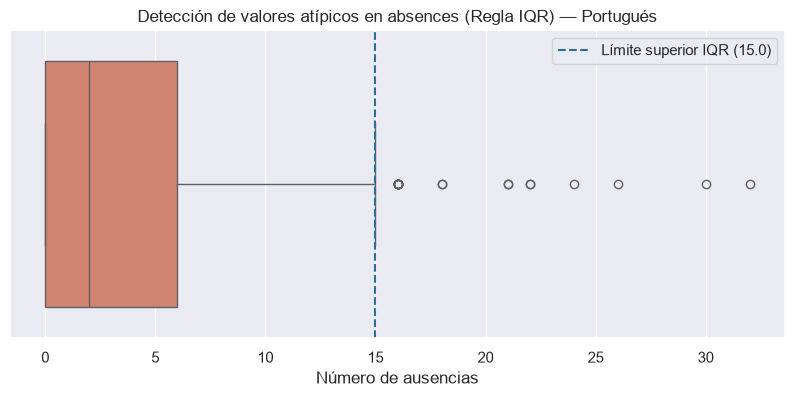

In [28]:
# 2.2 Visualización de atípicos en 'absences' mediante boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(x=abs_validos, color="#e07a5f")
plt.axvline(limite_sup, color="#2a6f97", ls="--", label=f"Límite superior IQR ({limite_sup:.1f})")
plt.title("Detección de valores atípicos en absences (Regla IQR) — Portugués")
plt.xlabel("Número de ausencias")
plt.legend()
plt.show()

### **Interpretación de 2.2 — Decisión sobre valores atípicos**

**Detección.** Con la regla IQR ($Q_1 = 0$, $Q_3 = 6$, $IQR = 6$), el límite superior es $6 + 1{,}5 \times 6 = 15$ ausencias (el límite inferior es negativo, por lo que no hay atípicos por debajo de 0). Los registros con más de 15 ausencias (hasta un máximo de 32) se identifican como atípicos estadísticos.

**Decisión: conservar los valores atípicos.** No se eliminan ni se recortan estos registros por tres razones:
1. **Validez del dato:** No son errores de digitación; el rango de 16 a 32 faltas en un curso escolar es completamente verosímil.
2. **Señal real de riesgo académico:** El objetivo de la institución es detectar a tiempo a estudiantes en riesgo de reprobar o abandonar. Precisamente quienes acumulan más inasistencias representan casos reales de alerta temprana; eliminarlos o suavizarlos ocultaría el fenómeno que el modelo debe aprender.
3. **Coherencia con el Hallazgo 4 del EDA:** Como se observó en la Parte 1, incluso existen 15 estudiantes con `G3 = 0` que registran 0 ausencias (posibles retiros no registrados). Por ello, reducir aún más la variabilidad de `absences` perjudicaría la capacidad predictiva de los modelos, siendo más adecuado conservarlos y mitigar su efecto de escala mediante `StandardScaler`.

## 2.3 Codificación, escalado, Pipeline con ColumnTransformer y división 80/20

In [29]:
# 2.3 Separación de variables predictoras y variable objetivo
# Nota: 'G3' es el objetivo de regresión; además se deja definida la referencia de 'aprueba' (G3 >= 10)
X_con_notas = df_prep.drop(columns=["G3"])          # Incluye G1 y G2 (para Modelo A)
X_sin_notas = df_prep.drop(columns=["G1", "G2", "G3"])  # Sin G1 ni G2 (para Modelo B y Reg. Logística)
y_reg = df_prep["G3"]
y_clf = (df_prep["G3"] >= 10).astype(int)

# División 80 % entrenamiento / 20 % prueba usando la semilla justificada SEED = 2026
# Se usan los mismos índices para que Modelo A, Modelo B y Clasificación evalúen exactamente los mismos estudiantes
idx_train, idx_test = train_test_split(
    df_prep.index, test_size=0.20, random_state=SEED, stratify=y_clf
)

X_train_A, X_test_A = X_con_notas.loc[idx_train], X_con_notas.loc[idx_test]
X_train_B, X_test_B = X_sin_notas.loc[idx_train], X_sin_notas.loc[idx_test]
y_train_reg, y_test_reg = y_reg.loc[idx_train], y_reg.loc[idx_test]
y_train_clf, y_test_clf = y_clf.loc[idx_train], y_clf.loc[idx_test]

print(f"Entrenamiento: {len(idx_train)} registros ({len(idx_train)/len(df_prep)*100:.1f} %)")
print(f"Prueba:        {len(idx_test)} registros ({len(idx_test)/len(df_prep)*100:.1f} %)")

Entrenamiento: 519 registros (80.0 %)
Prueba:        130 registros (20.0 %)


In [30]:
# 2.3 Definición del ColumnTransformer y Pipeline de preprocesamiento
def crear_preprocesador(X_df):
    """Construye un ColumnTransformer con imputación, One-Hot Encoding y escalado."""
    cols_num = X_df.select_dtypes(include=["number"]).columns.tolist()
    cols_cat = X_df.select_dtypes(exclude=["number"]).columns.tolist()

    pipe_num = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    pipe_cat = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
    ])

    preprocesador = ColumnTransformer(transformers=[
        ("num", pipe_num, cols_num),
        ("cat", pipe_cat, cols_cat)
    ])
    return preprocesador, cols_num, cols_cat

# Preprocesador A (con G1 y G2) y Preprocesador B (sin G1 ni G2)
preproc_A, num_A, cat_A = crear_preprocesador(X_train_A)
preproc_B, num_B, cat_B = crear_preprocesador(X_train_B)

# Ajuste (fit) ÚNICAMENTE sobre el conjunto de entrenamiento para evitar fuga de datos
X_train_A_proc = preproc_A.fit_transform(X_train_A)
X_test_A_proc  = preproc_A.transform(X_test_A)

X_train_B_proc = preproc_B.fit_transform(X_train_B)
X_test_B_proc  = preproc_B.transform(X_test_B)

print(f"Modelo A -> Numéricas: {len(num_A)}, Categóricas: {len(cat_A)} | Shape transformado train: {X_train_A_proc.shape}, test: {X_test_A_proc.shape}")
print(f"Modelo B -> Numéricas: {len(num_B)}, Categóricas: {len(cat_B)} | Shape transformado train: {X_train_B_proc.shape}, test: {X_test_B_proc.shape}")

Modelo A -> Numéricas: 15, Categóricas: 17 | Shape transformado train: (519, 41), test: (130, 41)
Modelo B -> Numéricas: 13, Categóricas: 17 | Shape transformado train: (519, 39), test: (130, 39)


In [31]:
# 2.3 Verificación de cero nulos después del Pipeline
print("Nulos en X_train_A_proc:", np.isnan(X_train_A_proc).sum())
print("Nulos en X_test_A_proc: ", np.isnan(X_test_A_proc).sum())
print("Nulos en X_train_B_proc:", np.isnan(X_train_B_proc).sum())
print("Nulos en X_test_B_proc: ", np.isnan(X_test_B_proc).sum())

Nulos en X_train_A_proc: 0
Nulos en X_test_A_proc:  0
Nulos en X_train_B_proc: 0
Nulos en X_test_B_proc:  0


### **Interpretación de 2.3**

**Necesidad de One-Hot Encoding.** Los modelos de regresión lineal y logística requieren entradas numéricas. Como las 17 variables categóricas (`school`, `sex`, `Mjob`, `Fjob`, `higher`, etc.) son nominales y no tienen orden numérico natural, asignarles enteros arbitrarios introduciría jerarquías falsas. Con `OneHotEncoder(drop="first", handle_unknown="ignore")` se representan mediante variables binarias evitando además la trampa de multicolinealidad perfecta (*dummy variable trap*).

**Necesidad de escalado numérico.** Las variables numéricas tienen rangos muy distintos (por ejemplo, `absences` llega hasta 32, `age` de 15 a 22, mientras `studytime` va de 1 a 4). Aplicar `StandardScaler` (media 0 y desviación estándar 1) evita que variables con mayor magnitud dominen el ajuste, acelera la convergencia de la regresión logística, hace comparables los coeficientes y es indispensable si se aplican penalizaciones Ridge o Lasso.

**Integración en `Pipeline` con `ColumnTransformer` y división 80/20.** Primero se divide el dataset en 80 % entrenamiento (519 estudiantes) y 20 % prueba (130 estudiantes) con `stratify=y_clf` para mantener la misma proporción de aprobados y reprobados en ambos conjuntos. Luego, el `Pipeline` ajusta (`fit_transform`) las medianas, medias y desviaciones estándar exclusivamente sobre entrenamiento y solo aplica `transform` en prueba, garantizando que no exista fuga de datos (*data leakage*). Se dejan listos `preproc_A` (con `G1` y `G2`) y `preproc_B` (sin `G1` ni `G2`) para las Partes 3 y 4.

**Justificación de la semilla (`SEED = 2026`).** Se eligió el número `2026` (distinto de 42) por corresponder al año académico en el que se desarrolla el proyecto, garantizando reproducibilidad total en la generación de valores faltantes y en la partición 80/20.

# Parte 3. Regresión lineal múltiple: predecir G3

En esta parte entrenamos dos modelos de regresión lineal para predecir la nota final `G3` (escala 0–20):

- **Modelo A:** todas las variables, **incluidas** `G1` y `G2` (notas del 1.er y 2.º período).
- **Modelo B:** todas las variables **excepto** `G1` y `G2`.

Ambos usan la misma partición 80/20 (`SEED = 2026`) y el mismo preprocesamiento de la Parte 2, ahora unido al modelo en un `Pipeline`.

## 3.0 Librerías

In [32]:
# ============================================================
# 3.0 Librerías para la Parte 3 (regresión lineal múltiple)
# ============================================================
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson, jarque_bera

# Comprobación rápida de que las variables de la Parte 2 existen en memoria
for nombre in ["X_train_A", "X_test_A", "X_train_B", "X_test_B",
               "y_train_reg", "y_test_reg", "preproc_A", "preproc_B", "SEED"]:
    assert nombre in globals(), f"Falta '{nombre}': ejecute primero las Partes 1 y 2"
print("Variables de la Parte 2 disponibles. SEED =", SEED)

Variables de la Parte 2 disponibles. SEED = 2026


## 3.1 Entrenamiento de los Modelos A y B

In [33]:
# ============================================================
# 3.1 Entrenamiento de los Modelos A y B dentro de un Pipeline completo
#     (preprocesamiento + regresión lineal)
# ============================================================
# clone() crea una copia "sin entrenar" del ColumnTransformer de la Parte 2,
# así cada Pipeline aprende sus medianas/medias/desviaciones solo con su train.
pipe_A = Pipeline(steps=[
    ("preprocesamiento", clone(preproc_A)),   # con G1 y G2
    ("modelo", LinearRegression())
])

pipe_B = Pipeline(steps=[
    ("preprocesamiento", clone(preproc_B)),   # sin G1 ni G2
    ("modelo", LinearRegression())
])

# Entrenamiento SOLO con el 80 % de entrenamiento
pipe_A.fit(X_train_A, y_train_reg)
pipe_B.fit(X_train_B, y_train_reg)

# Predicciones sobre el 20 % de prueba (y sobre train, para detectar sobreajuste)
y_pred_A = pipe_A.predict(X_test_A)
y_pred_B = pipe_B.predict(X_test_B)
y_pred_A_train = pipe_A.predict(X_train_A)
y_pred_B_train = pipe_B.predict(X_train_B)

print("Modelo A -> variables de entrada:", X_train_A.shape[1],
      "| columnas tras el preprocesamiento:", len(pipe_A[:-1].get_feature_names_out()))
print("Modelo B -> variables de entrada:", X_train_B.shape[1],
      "| columnas tras el preprocesamiento:", len(pipe_B[:-1].get_feature_names_out()))

Modelo A -> variables de entrada: 32 | columnas tras el preprocesamiento: 41
Modelo B -> variables de entrada: 30 | columnas tras el preprocesamiento: 39


### **Interpretación de 3.1**

El Modelo A recibe 32 variables (todas menos `G3`) y el Modelo B 30 (sin `G1` ni `G2`). Después de la imputación, el escalado y el One-Hot Encoding con `drop="first"` quedan 41 y 39 columnas, respectivamente. La diferencia de dos columnas corresponde exactamente a `G1` y `G2`.

Cada modelo es un `Pipeline` que une el `ColumnTransformer` de la Parte 2 con una `LinearRegression`. Usamos `clone()` para que cada Pipeline aprenda sus propias medianas, medias y desviaciones **solo con los 519 estudiantes de entrenamiento**; los 130 de prueba únicamente se transforman. Así evitamos la fuga de datos en el preprocesamiento. Como ambos modelos usan los mismos `idx_train` e `idx_test`, se evalúan sobre los mismos 130 estudiantes y la comparación es justa.

## 3.2 Métricas en el conjunto de prueba (MSE, RMSE y R²)

- **MSE** (error cuadrático medio): promedio de los errores al cuadrado; está en puntos² y castiga más los errores grandes.
- **RMSE** (raíz del MSE): el mismo error expresado en **puntos de nota (0–20)**, por eso es la métrica más fácil de interpretar.
- **R²** (coeficiente de determinación): proporción de la variabilidad de G3 que explica el modelo. 1 = perfecto; 0 = igual que predecir siempre el promedio; negativo = peor que el promedio.

Además de las métricas de prueba que pide el enunciado, la tabla incluye una **línea base** (predecir siempre el promedio de G3 de entrenamiento), el **MAE** y las métricas de **entrenamiento**. Después se agrega una **validación cruzada** de 5 particiones sobre el entrenamiento, que mide el sobreajuste sin depender de una sola partición.

In [34]:
# ============================================================
# 3.2 Métricas MSE, RMSE y R² en el conjunto de PRUEBA
# ============================================================
def calcular_metricas(y_real, y_pred):
    """Devuelve MSE, RMSE, MAE y R² con scikit-learn."""
    mse = mean_squared_error(y_real, y_pred)
    return {
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),   # misma unidad que G3 (puntos sobre 20)
        "MAE": mean_absolute_error(y_real, y_pred),
        "R2": r2_score(y_real, y_pred),
    }

# Línea base: predecir siempre la media de G3 del entrenamiento (R² ≈ 0)
y_pred_base = np.full(len(y_test_reg), y_train_reg.mean())

tabla_metricas = pd.DataFrame({
    "Línea base (media)": calcular_metricas(y_test_reg, y_pred_base),
    "Modelo A (con G1, G2) - test": calcular_metricas(y_test_reg, y_pred_A),
    "Modelo B (sin G1, G2) - test": calcular_metricas(y_test_reg, y_pred_B),
    "Modelo A - train": calcular_metricas(y_train_reg, y_pred_A_train),
    "Modelo B - train": calcular_metricas(y_train_reg, y_pred_B_train),
}).T.round(3)
tabla_metricas

,MSE,RMSE,MAE,R2
Línea base (media),7.976,2.824,2.171,-0.004
"Modelo A (con G1, G2) - test",1.015,1.007,0.734,0.872
"Modelo B (sin G1, G2) - test",5.808,2.410,1.820,0.269
Modelo A - train,1.599,1.264,0.786,0.855
Modelo B - train,7.029,2.651,1.923,0.363


In [35]:
# 3.2 Validación cruzada (5 particiones) sobre el conjunto de ENTRENAMIENTO
# Sirve para (a) medir el sobreajuste sin depender de una sola partición y
# (b) saber si el resultado de prueba es típico o fruto de una partición favorable.
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
resultados_cv = {}
for nombre, pipe, X_tr in [("Modelo A", pipe_A, X_train_A), ("Modelo B", pipe_B, X_train_B)]:
    r2_cv = cross_val_score(clone(pipe), X_tr, y_train_reg, cv=kf, scoring="r2")
    rmse_cv = -cross_val_score(clone(pipe), X_tr, y_train_reg, cv=kf, scoring="neg_root_mean_squared_error")
    resultados_cv[nombre] = {"R2 CV (media)": r2_cv.mean(), "R2 CV (desv.)": r2_cv.std(),
                             "RMSE CV (media)": rmse_cv.mean()}
display(pd.DataFrame(resultados_cv).T.round(3))

# Cifras que se citan en la interpretación de 3.2
print(f"Rango de predicciones del Modelo B en prueba: {y_pred_B.min():.2f} a {y_pred_B.max():.2f} "
      f"| G3 real en prueba: {y_test_reg.min()} a {y_test_reg.max()}")
print("Estudiantes con G3 = 0 -> train:", int((y_train_reg == 0).sum()), "| test:", int((y_test_reg == 0).sum()))
print(f"Varianza de G3 -> train: {y_train_reg.var(ddof=0):.2f} | test: {y_test_reg.var(ddof=0):.2f}")

,R2 CV (media),R2 CV (desv.),RMSE CV (media)
Modelo A,0.820,0.019,1.403
Modelo B,0.234,0.020,2.888


Rango de predicciones del Modelo B en prueba: 5.59 a 15.68 | G3 real en prueba: 0 a 18
Estudiantes con G3 = 0 -> train: 14 | test: 1
Varianza de G3 -> train: 11.03 | test: 7.95


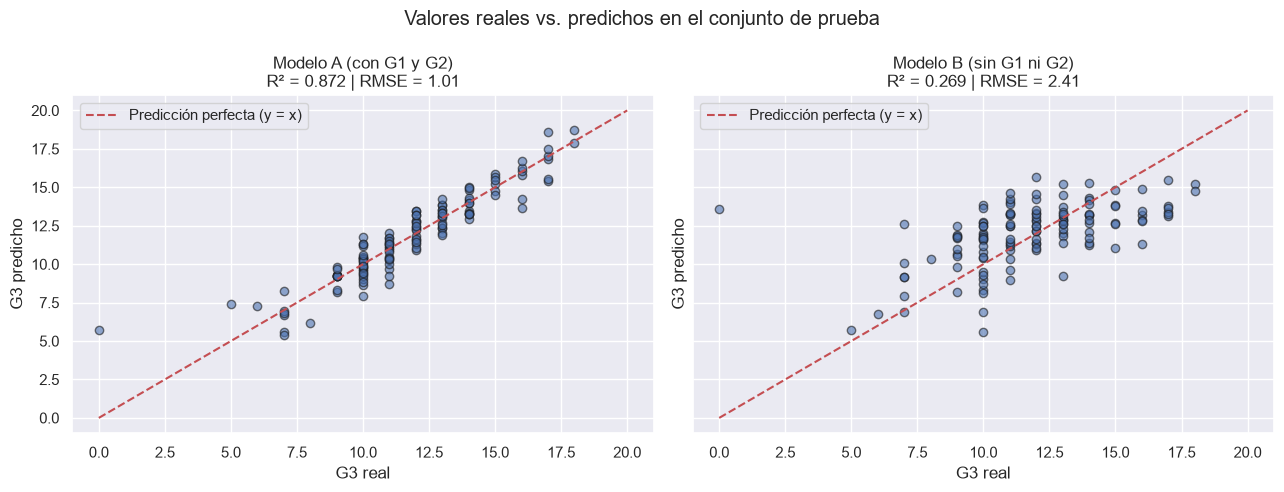

In [36]:
# 3.2 Gráfico: valores reales vs. predichos (prueba) para A y B
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, y_pred, titulo in zip(axes, [y_pred_A, y_pred_B],
                              ["Modelo A (con G1 y G2)", "Modelo B (sin G1 ni G2)"]):
    ax.scatter(y_test_reg, y_pred, alpha=0.6, edgecolor="k")
    ax.plot([0, 20], [0, 20], "r--", label="Predicción perfecta (y = x)")
    r2 = r2_score(y_test_reg, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred))
    ax.set_title(f"{titulo}\nR² = {r2:.3f} | RMSE = {rmse:.2f}")
    ax.set_xlabel("G3 real")
    ax.set_ylabel("G3 predicho")
    ax.legend()
plt.suptitle("Valores reales vs. predichos en el conjunto de prueba")
plt.tight_layout()
plt.show()

In [37]:
# 3.2 Coeficientes del Modelo B
# Ojo: los dos tipos de variables NO están en la misma escala, por eso se muestran por separado.
#  - Numéricas (estandarizadas): cambio en G3 por 1 desviación estándar de la variable.
#  - Dummies (0/1, sin escalar): diferencia en G3 frente a la categoría de referencia.
nombres_B = pipe_B[:-1].get_feature_names_out()
coef_B = pd.Series(pipe_B.named_steps["modelo"].coef_, index=nombres_B)
print("Intercepto Modelo B:", round(pipe_B.named_steps["modelo"].intercept_, 3))

coef_num_B = coef_B[coef_B.index.str.startswith("num__")]
coef_cat_B = coef_B[coef_B.index.str.startswith("cat__")]

# Desviaciones estándar aprendidas por el StandardScaler en train -> coeficiente en unidades originales
desv_train = pipe_B.named_steps["preprocesamiento"].named_transformers_["num"].named_steps["scaler"].scale_
tabla_coef_num = pd.DataFrame({
    "coef. por 1 desv. estándar": coef_num_B.to_numpy(),
    "desv. estándar (train)": desv_train,
    "coef. por 1 unidad original": coef_num_B.to_numpy() / desv_train,
}, index=coef_num_B.index)
tabla_coef_num = tabla_coef_num.reindex(coef_num_B.abs().sort_values(ascending=False).index)
display(tabla_coef_num.round(3))

top_coef_cat = coef_cat_B.reindex(coef_cat_B.abs().sort_values(ascending=False).index).head(8)
display(top_coef_cat.round(3).to_frame("diferencia vs. categoría de referencia (puntos)"))

Intercepto Modelo B: 11.642


,coef. por 1 desv. estándar,desv. estándar (train),coef. por 1 unidad original
num__failures,-0.831,0.614,-1.354
num__studytime,0.263,0.802,0.328
num__health,-0.259,1.442,-0.180
num__Walc,-0.217,1.292,-0.168
num__freetime,-0.193,1.052,-0.183
num__Medu,0.175,1.131,0.154
num__age,0.164,1.198,0.137
num__absences,-0.139,4.483,-0.031
num__traveltime,0.130,0.737,0.177
num__Fedu,0.117,1.096,0.106


,diferencia vs. categoría de referencia (puntos)
cat__higher_yes,1.977
cat__school_MS,-1.431
cat__schoolsup_yes,-1.412
cat__Fjob_services,-1.272
cat__Fjob_health,-0.999
cat__Mjob_health,0.732
cat__sex_M,-0.657
cat__guardian_mother,-0.618


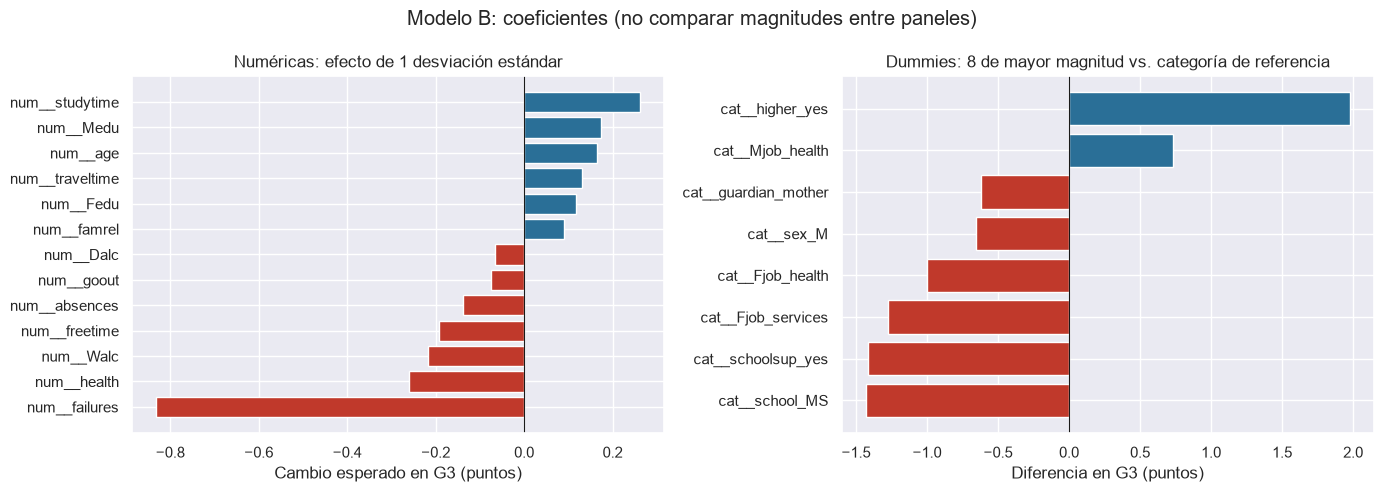

In [38]:
# 3.2 Gráfico de coeficientes del Modelo B (un panel por tipo de variable, escalas distintas)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, serie, titulo, etiqueta in [
    (axes[0], coef_num_B.sort_values(), "Numéricas: efecto de 1 desviación estándar", "Cambio esperado en G3 (puntos)"),
    (axes[1], top_coef_cat.sort_values(), "Dummies: 8 de mayor magnitud vs. categoría de referencia", "Diferencia en G3 (puntos)"),
]:
    ax.barh(serie.index, serie.values, color=["#c0392b" if v < 0 else "#2a6f97" for v in serie.values])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta)
plt.suptitle("Modelo B: coeficientes (no comparar magnitudes entre paneles)")
plt.tight_layout()
plt.show()

### **Interpretación de 3.2**

**Comparación de R².** En prueba, el Modelo A explica el **87,2 %** de la variabilidad de la nota final (R² = 0,872), mientras que el Modelo B explica solo el **26,9 %** (R² = 0,269). La diferencia se debe a que `G1` y `G2` están muy correlacionadas con `G3` (0,83 y 0,92, Parte 1.3): la nota final se parece mucho a las notas de los períodos anteriores.

**Error en la escala de la nota.** El RMSE del Modelo A es **1,01 puntos** sobre 20 (MAE 0,73) y el del Modelo B es **2,41 puntos** (MAE 1,82). En la práctica, un error de ±2,4 puntos es grande cerca de la nota de aprobación (10): un estudiante con 9 real podría aparecer con 11,4 predicho. Por eso el Modelo B sirve para ordenar o priorizar estudiantes, no para anunciar la nota exacta de cada uno.

**Comparación con la línea base.** Predecir siempre el promedio de entrenamiento da un RMSE de 2,82 y un R² ≈ 0. El Modelo B baja el MSE de 7,98 a 5,81 (un 27 % menos), así que sí aporta información, aunque de forma moderada. El Modelo A lo baja a 1,02 (un 87 % menos).

**Entrenamiento, prueba y validación cruzada.** El Modelo A obtiene R² de 0,855 en train, 0,872 en test y 0,820 ± 0,019 en validación cruzada: generaliza bien.

En el Modelo B, comparar train y test directamente es engañoso. El R² baja de 0,363 a 0,269, pero el RMSE es *menor* en test (2,41) que en train (2,65). La razón es que el conjunto de prueba tiene solo 1 de los 15 estudiantes con `G3 = 0` (14 quedaron en entrenamiento), así que sus notas varían menos: la varianza de G3 es 7,95 en test frente a 11,03 en train. Con un denominador más pequeño, el R² baja aunque los errores sean menores.

La validación cruzada de 5 particiones sobre el entrenamiento resuelve la duda. El R² del Modelo B es 0,234 ± 0,020 (RMSE 2,89), claramente menor que el 0,363 de ajuste en train: hay un **sobreajuste moderado**, esperable con 39 columnas para 519 estudiantes. Además, muestra que el R² de prueba (0,269) es coherente con el rendimiento típico del modelo y no fruto de una partición favorable. Dos precauciones. La desviación de ±0,020 corresponde a esta división concreta en 5 partes; con otras divisiones la dispersión entre partes puede ser bastante mayor, así que el dato robusto es la media (≈ 0,23). Y como el test es una sola partición de 130 estudiantes, su R² podría cambiar de forma apreciable con otra semilla, sobre todo según cuántos estudiantes con `G3 = 0` caigan en él.

**Gráfico real vs. predicho.** En el Modelo A los puntos siguen la diagonal. En el Modelo B las predicciones van de 5,59 a 15,68 aunque las notas reales van de 0 a 18: el modelo "aplana" hacia el promedio y no se atreve a predecir notas extremas. El punto más alejado es el único estudiante de prueba con `G3 = 0`, al que el Modelo B le asigna cerca de 13,6.

**Variables más influyentes del Modelo B.** Las variables numéricas están estandarizadas y las dummies valen 0 o 1, así que sus coeficientes **no están en la misma escala** y se analizan por separado:

- **Numéricas** (cambio en G3 por una desviación estándar; entre paréntesis, por unidad original):
  - `failures` −0,83 (−1,35 puntos por cada reprobación previa), coherente con el Hallazgo 1.
  - `studytime` +0,26 (+0,33 por cada nivel de tiempo de estudio), coherente con el Hallazgo 3.
  - `health` −0,26 y `Walc` −0,22 (−0,17 por cada nivel de consumo de alcohol en fin de semana).
  - El resto tiene efectos pequeños. `absences` resta solo 0,03 puntos por falta.
- **Dummies** (diferencia en G3 frente a la categoría de referencia):
  - `higher_yes` +1,98 frente a quien no desea estudios superiores, coherente con el Hallazgo 5.
  - `school_MS` −1,43 frente a la escuela GP.
  - `schoolsup_yes` −1,41. No significa que el apoyo escolar baje la nota: lo más probable es que el apoyo se asigne a quienes ya tienen dificultades (causalidad inversa).
  - `Fjob_services` −1,27 frente a padre `at_home`. Su VIF (4,64) está cerca del umbral de 5, así que es un coeficiente poco estable.
  - `Fjob_health` −1,00. No tiene ese problema (VIF 1,79), pero corresponde a solo 23 padres en todo el dataset, así que también debe leerse con cautela.

No se deben comparar magnitudes entre los dos grupos. Por ejemplo, una reprobación (−1,35) pesa menos que `higher_yes` (+1,98), pero tres reprobaciones (≈ −4,1) pesan más. Todas estas relaciones son asociaciones, no causas.

## 3.3 Cálculo manual de las métricas del Modelo B con NumPy

Sea $y_i$ la nota real, $\hat{y}_i$ la predicha y $n$ el número de estudiantes de prueba (130):

$$e_i = y_i - \hat{y}_i$$

$$MSE = \frac{1}{n}\sum_{i=1}^{n} e_i^{2} \qquad RMSE = \sqrt{MSE}$$

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}$$

donde $\bar{y}$ es el promedio de las notas reales del conjunto de prueba. Calculamos las tres métricas y las comparamos con scikit-learn.

In [39]:
# ============================================================
# 3.3 Cálculo "a mano" con NumPy de MSE, RMSE y R² del Modelo B
#     y comparación con scikit-learn
# ============================================================
y_real = y_test_reg.to_numpy(dtype=float)   # valores reales de G3 (prueba)
y_hat = np.asarray(y_pred_B, dtype=float)   # predicciones del Modelo B
n_test = y_real.size

errores = y_real - y_hat                    # e_i = y_i - ŷ_i
mse_np = np.sum(errores ** 2) / n_test      # MSE = (1/n) Σ e_i²
rmse_np = np.sqrt(mse_np)                   # RMSE = √MSE
ss_res = np.sum(errores ** 2)               # SS_res = Σ (y_i - ŷ_i)²
ss_tot = np.sum((y_real - y_real.mean()) ** 2)  # SS_tot = Σ (y_i - ȳ)²
r2_np = 1 - ss_res / ss_tot                 # R² = 1 - SS_res / SS_tot

mse_sk = mean_squared_error(y_test_reg, y_pred_B)
rmse_sk = np.sqrt(mse_sk)
r2_sk = r2_score(y_test_reg, y_pred_B)

comparacion = pd.DataFrame({
    "NumPy (a mano)": [mse_np, rmse_np, r2_np],
    "scikit-learn": [mse_sk, rmse_sk, r2_sk],
}, index=["MSE", "RMSE", "R2"])
comparacion["Diferencia absoluta"] = (comparacion["NumPy (a mano)"] - comparacion["scikit-learn"]).abs()
comparacion["¿Coinciden? (np.isclose)"] = np.isclose(comparacion["NumPy (a mano)"], comparacion["scikit-learn"])
print(comparacion.to_string(float_format=lambda v: f"{v:.10f}"))

      NumPy (a mano)  scikit-learn  Diferencia absoluta  ¿Coinciden? (np.isclose)
MSE     5.8076474950  5.8076474950         0.0000000000                      True
RMSE    2.4099061175  2.4099061175         0.0000000000                      True
R2      0.2691791313  0.2691791313         0.0000000000                      True


### **Interpretación de 3.3**

Los valores calculados a mano con NumPy coinciden exactamente con los de scikit-learn: MSE = 5,8076474950, RMSE = 2,4099061175 y R² = 0,2691791313. La diferencia absoluta es 0 hasta el décimo decimal y `np.isclose` devuelve `True` en las tres métricas.

Esto confirma que aplicamos bien las fórmulas y que entendemos qué hace scikit-learn por dentro: el MSE divide entre $n$ (no entre $n-p-1$), y el $SS_{tot}$ del R² usa el promedio de las notas reales del propio conjunto de prueba.

## 3.4 Revisión de los 5 supuestos de la regresión lineal (Modelo B)

Analizamos los residuos $e_i = y_i - \hat{y}_i$ del conjunto de **entrenamiento** (n = 519), que es donde se estimaron los coeficientes. Para obtener las pruebas estadísticas ajustamos el mismo Modelo B con `statsmodels.OLS` y comprobamos que los coeficientes coinciden con los de scikit-learn.

Para cada supuesto presentamos un gráfico, una prueba estadística y una conclusión. Criterio: p-valor < 0,05 ⇒ se rechaza H0 (en todas las pruebas, H0 = "el supuesto se cumple").

In [40]:
# ============================================================
# 3.4 Supuestos del Modelo B: preparación
#     Se analizan los residuos del conjunto de ENTRENAMIENTO (n = 519),
#     que es donde se estimaron los coeficientes por mínimos cuadrados.
# ============================================================
prep_B_ajustado = pipe_B.named_steps["preprocesamiento"]
X_train_B_mat = prep_B_ajustado.transform(X_train_B)     # matriz ya imputada/escalada/codificada
X_train_B_df = pd.DataFrame(X_train_B_mat, columns=nombres_B, index=X_train_B.index)

# Mismo modelo ajustado con statsmodels (OLS) para obtener pruebas estadísticas
X_train_B_const = sm.add_constant(X_train_B_df)
ols_B = sm.OLS(y_train_reg, X_train_B_const).fit()

# Verificación: OLS de statsmodels y LinearRegression de sklearn dan los mismos coeficientes
print("¿Coeficientes iguales sklearn vs statsmodels?:",
      np.allclose(ols_B.params.drop("const").to_numpy(), pipe_B.named_steps["modelo"].coef_, atol=1e-6))

ajustados_B = ols_B.fittedvalues            # ŷ en entrenamiento
residuos_B = ols_B.resid                    # e = y - ŷ en entrenamiento
residuos_std_B = ols_B.get_influence().resid_studentized_internal
print("Media de los residuos (≈ 0):", round(residuos_B.mean(), 6))
print(f"R² de entrenamiento (statsmodels): {ols_B.rsquared:.3f} | R² ajustado: {ols_B.rsquared_adj:.3f}")

¿Coeficientes iguales sklearn vs statsmodels?: True
Media de los residuos (≈ 0): -0.0
R² de entrenamiento (statsmodels): 0.363 | R² ajustado: 0.311


Los coeficientes de `statsmodels.OLS` coinciden con los de scikit-learn (`True`), así que los diagnósticos siguientes corresponden exactamente al Modelo B. La media de los residuos es 0, como corresponde a mínimos cuadrados con intercepto. El R² de entrenamiento es 0,363 y el R² ajustado 0,311. La diferencia entre ambos refleja el costo de usar 39 predictoras.

### Supuesto 1 – Linealidad

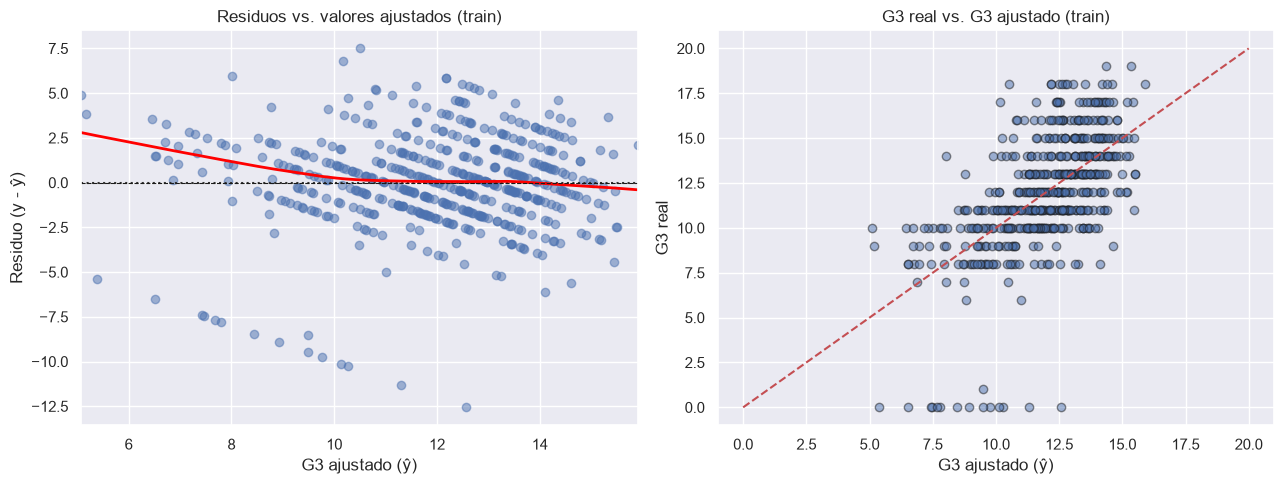

RESET de Ramsey: F = 0.019, p-valor = 0.8908
Conclusión: No se rechaza H0 -> linealidad aceptable


In [41]:
# ------------------------------------------------------------
# Supuesto 1: LINEALIDAD
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# (a) Residuos vs. valores ajustados con curva LOWESS: debería ser una nube plana alrededor de 0
sns.residplot(x=ajustados_B, y=residuos_B, lowess=True, ax=axes[0],
              scatter_kws={"alpha": 0.5}, line_kws={"color": "red", "lw": 2})
axes[0].axhline(0, color="k", ls="--", lw=0.8)
axes[0].set_title("Residuos vs. valores ajustados (train)")
axes[0].set_xlabel("G3 ajustado (ŷ)")
axes[0].set_ylabel("Residuo (y - ŷ)")
# (b) Reales vs. ajustados: los puntos deberían seguir la diagonal
axes[1].scatter(ajustados_B, y_train_reg, alpha=0.5, edgecolor="k")
axes[1].plot([0, 20], [0, 20], "r--")
axes[1].set_title("G3 real vs. G3 ajustado (train)")
axes[1].set_xlabel("G3 ajustado (ŷ)")
axes[1].set_ylabel("G3 real")
plt.tight_layout()
plt.show()

# Prueba RESET de Ramsey. H0: la forma lineal es adecuada (no faltan términos no lineales)
reset_B = linear_reset(ols_B, power=2, use_f=True)
print(f"RESET de Ramsey: F = {float(reset_B.fvalue):.3f}, p-valor = {float(reset_B.pvalue):.4f}")
print("Conclusión:", "No se rechaza H0 -> linealidad aceptable" if reset_B.pvalue >= 0.05
      else "Se rechaza H0 -> hay indicios de no linealidad")

**Conclusión – Linealidad: se cumple.**

En el gráfico de residuos vs. ajustados, la curva LOWESS se mantiene prácticamente plana alrededor de 0 para predicciones entre 9 y 15, donde está la gran mayoría de los estudiantes. Solo se levanta en el extremo izquierdo (predicciones menores a 9), donde hay pocos puntos.

Se observan franjas diagonales paralelas. No son un problema de forma funcional: como `G3` solo toma valores enteros, cada franja corresponde a una misma nota real (residuo = nota − ŷ). La franja separada en la parte inferior, con residuos entre −5 y −12,5, la forman los estudiantes con `G3 = 0`.

La prueba RESET de Ramsey no encuentra evidencia de no linealidad (F = 0,019; p = 0,891 > 0,05).

### Supuesto 2 – Independencia de los residuos

Estadístico de Durbin-Watson: 2.059  (≈ 2 sin autocorrelación; 1.5–2.5 aceptable)


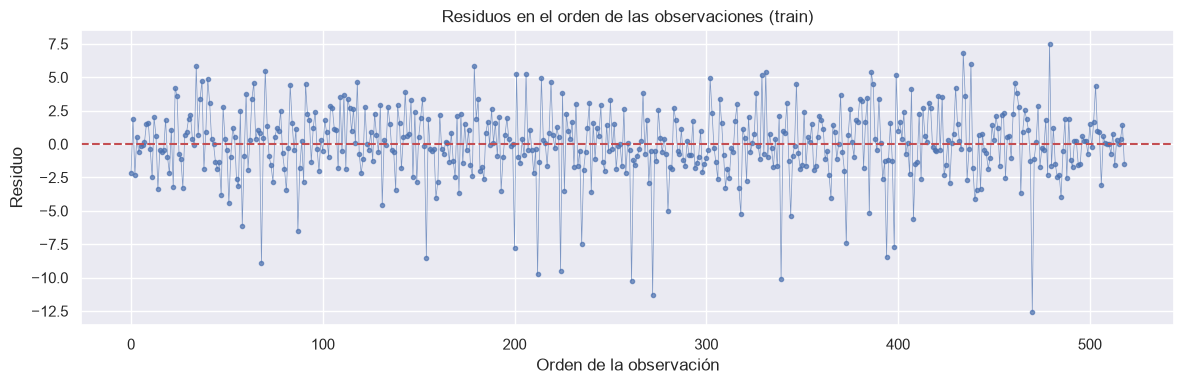

In [42]:
# ------------------------------------------------------------
# Supuesto 2: INDEPENDENCIA de los residuos
# ------------------------------------------------------------
dw_B = durbin_watson(residuos_B)
print(f"Estadístico de Durbin-Watson: {dw_B:.3f}  (≈ 2 sin autocorrelación; 1.5–2.5 aceptable)")

plt.figure(figsize=(12, 4))
plt.plot(np.arange(len(residuos_B)), residuos_B.to_numpy(), marker="o", ls="-", lw=0.5, ms=3, alpha=0.7)
plt.axhline(0, color="r", ls="--")
plt.title("Residuos en el orden de las observaciones (train)")
plt.xlabel("Orden de la observación")
plt.ylabel("Residuo")
plt.tight_layout()
plt.show()

**Conclusión – Independencia: se cumple.**

El estadístico de Durbin-Watson es **2,059**, muy cerca de 2 y dentro del rango aceptable (1,5–2,5). El gráfico de residuos en orden no muestra rachas largas de residuos positivos o negativos: se ve como ruido alrededor de 0.

Hay que matizar el resultado. `train_test_split` baraja las filas, así que un DW cercano a 2 es casi esperable: el estadístico depende del orden de las filas, y aquí ese orden es aleatorio. Por eso el DW es solo un apoyo, no la prueba principal. El argumento principal es el diseño de los datos: cada fila es un estudiante distinto, medido una sola vez (datos transversales). Una posible fuente de dependencia es que los estudiantes de una misma escuela, o de un mismo curso, comparten profesores y contexto. Incluir la variable `school` en el modelo recoge la diferencia promedio entre escuelas, pero no prueba que no haya dependencia dentro de cada una. La conclusión se apoya, por tanto, en el diseño de los datos.

### Supuesto 3 – Homocedasticidad

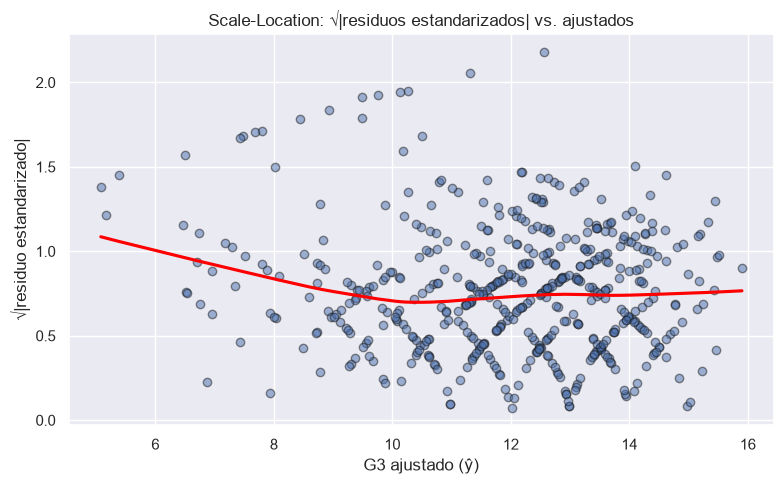

Breusch-Pagan: LM = 84.573, p-valor = 0.0000 | F = 2.391, p-valor = 0.0000
Conclusión: Se rechaza H0 -> hay heterocedasticidad
Puntos con √|residuo estandarizado| > 1,5: 18 | de ellos con G3 = 0: 13


In [43]:
# ------------------------------------------------------------
# Supuesto 3: HOMOCEDASTICIDAD (varianza constante de los residuos)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(ajustados_B, np.sqrt(np.abs(residuos_std_B)), alpha=0.5, edgecolor="k")
sns.regplot(x=ajustados_B, y=np.sqrt(np.abs(residuos_std_B)), scatter=False, lowess=True,
            line_kws={"color": "red"}, ax=ax)
ax.set_title("Scale-Location: √|residuos estandarizados| vs. ajustados")
ax.set_xlabel("G3 ajustado (ŷ)")
ax.set_ylabel("√|residuo estandarizado|")
plt.tight_layout()
plt.show()

# Prueba de Breusch-Pagan. H0: los residuos son homocedásticos
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(residuos_B, X_train_B_const)
print(f"Breusch-Pagan: LM = {bp_lm:.3f}, p-valor = {bp_lm_p:.4f} | F = {bp_f:.3f}, p-valor = {bp_f_p:.4f}")
print("Conclusión:", "No se rechaza H0 -> homocedasticidad aceptable" if bp_lm_p >= 0.05
      else "Se rechaza H0 -> hay heterocedasticidad")

# ¿Quiénes son los puntos con residuo más alto?
alto = np.sqrt(np.abs(residuos_std_B)) > 1.5
print(f"Puntos con √|residuo estandarizado| > 1,5: {alto.sum()} | de ellos con G3 = 0: {int((y_train_reg.to_numpy()[alto] == 0).sum())}")

**Conclusión – Homocedasticidad: no se cumple.**

En el gráfico Scale-Location la línea roja está más alta para predicciones menores a 10 y luego se estabiliza: la dispersión de los residuos es mayor en los estudiantes con predicción baja. De los 18 puntos con √|residuo estandarizado| mayor a 1,5, 13 son estudiantes con `G3 = 0`.

La prueba de Breusch-Pagan confirma la heterocedasticidad (LM = 84,57; p < 0,0001).

**Consecuencia:** los coeficientes siguen siendo insesgados, así que las predicciones y el R² son válidos. Lo que deja de ser fiable son los errores estándar y los p-valores de cada coeficiente. Remedios posibles: usar errores estándar robustos (`fit(cov_type="HC3")` en statsmodels), tratar por separado a los estudiantes que abandonan, o transformar la variable objetivo.

### Supuesto 4 – Normalidad de los residuos

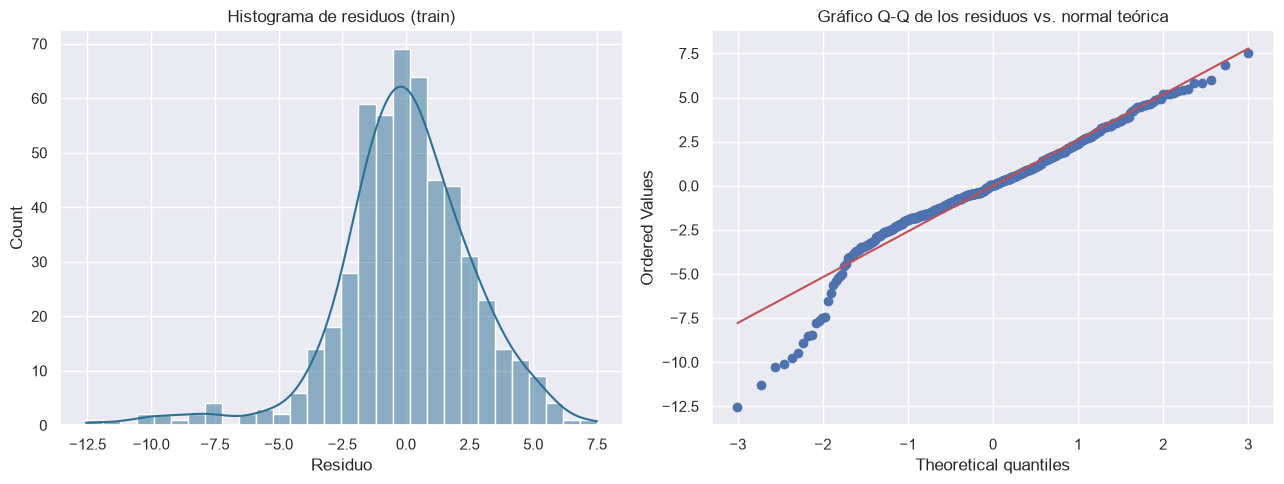

Shapiro-Wilk: W = 0.9486, p-valor = 1.894e-12
Jarque-Bera:  JB = 243.136, p-valor = 1.598e-53 | asimetría = -0.839, curtosis = 5.904 (normal: 0 y 3)
Conclusión: Se rechaza H0 -> los residuos NO son normales


In [44]:
# ------------------------------------------------------------
# Supuesto 4: NORMALIDAD de los residuos
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(residuos_B, kde=True, bins=30, ax=axes[0], color="#2a6f97")
axes[0].set_title("Histograma de residuos (train)")
axes[0].set_xlabel("Residuo")
stats.probplot(residuos_B, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q de los residuos vs. normal teórica")
plt.tight_layout()
plt.show()

sw_stat, sw_p = stats.shapiro(residuos_B)
jb_stat, jb_p, jb_skew, jb_kurt = jarque_bera(residuos_B)
print(f"Shapiro-Wilk: W = {sw_stat:.4f}, p-valor = {sw_p:.4g}")
print(f"Jarque-Bera:  JB = {jb_stat:.3f}, p-valor = {jb_p:.4g} | asimetría = {jb_skew:.3f}, curtosis = {jb_kurt:.3f} (normal: 0 y 3)")
print("Conclusión:", "No se rechaza H0 -> residuos compatibles con normalidad" if sw_p >= 0.05
      else "Se rechaza H0 -> los residuos NO son normales")

**Conclusión – Normalidad de los residuos: no se cumple.**

El histograma tiene forma de campana centrada en 0, pero con una **cola izquierda larga** (residuos de −5 a −12,5). En el gráfico Q-Q, el centro y la cola derecha siguen la recta, mientras que la cola izquierda se separa claramente.

Las pruebas lo confirman:
- Shapiro-Wilk: W = 0,9486, p ≈ 1,9 × 10⁻¹².
- Jarque-Bera: JB = 243,1, p ≈ 1,6 × 10⁻⁵³.
- Asimetría = −0,84 (normal: 0) y curtosis = 5,90 (normal: 3).

**Causa:** los 14 estudiantes de entrenamiento con `G3 = 0`, cuya nota real está muy por debajo de lo que predice el modelo. El análisis 3.6.1 lo confirma: sin ellos, el p-valor de Shapiro sube a 0,0067. Todavía se rechaza la normalidad, en parte porque la nota es discreta, pero la mejora es de unos diez órdenes de magnitud.

**Consecuencia:** con n = 519, por el Teorema Central del Límite, la distribución de los coeficientes es aproximadamente normal, así que la inferencia es razonable aunque no exacta. Las predicciones puntuales no dependen de este supuesto.

### Supuesto 5 – No multicolinealidad

In [45]:
# ------------------------------------------------------------
# Supuesto 5: NO MULTICOLINEALIDAD (VIF)
# ------------------------------------------------------------
vif_B = pd.DataFrame({
    "variable": X_train_B_const.columns,
    "VIF": [variance_inflation_factor(X_train_B_const.values, i)
            for i in range(X_train_B_const.shape[1])]
})
vif_B = vif_B[vif_B["variable"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)
print("Variables con VIF > 5:", (vif_B["VIF"] > 5).sum(), "| con VIF > 10:", (vif_B["VIF"] > 10).sum())
print("Número de condición de la matriz X (statsmodels):", round(ols_B.condition_number, 1))
vif_B.head(15).round(2)

Variables con VIF > 5: 0 | con VIF > 10: 0
Número de condición de la matriz X (statsmodels): 29.0


,variable,VIF
0,cat__Fjob_other,4.96
1,cat__Fjob_services,4.64
2,num__Medu,2.77
3,cat__Mjob_teacher,2.50
4,cat__Fjob_teacher,2.27
5,cat__Mjob_services,2.23
6,num__Fedu,2.19
7,cat__Mjob_other,2.10
8,num__Walc,2.08
9,cat__Mjob_health,1.92


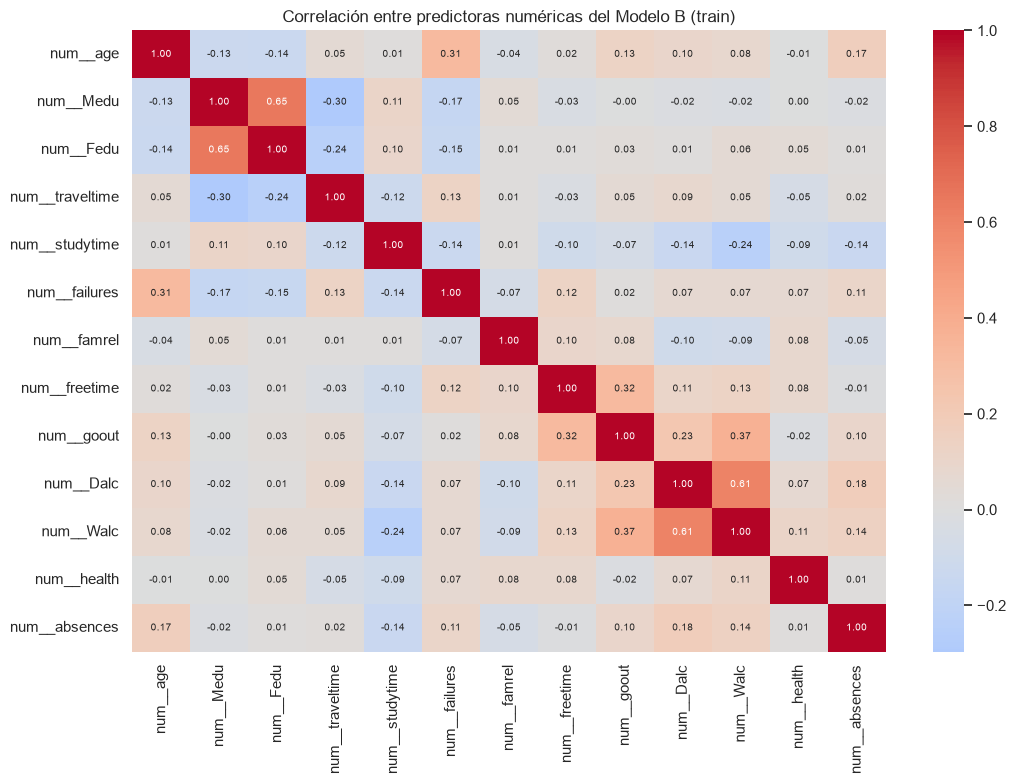

In [46]:
# Mapa de calor de correlaciones entre las predictoras NUMÉRICAS del Modelo B (ya imputadas y escaladas)
cols_num_B = [c for c in nombres_B if c.startswith("num__")]
plt.figure(figsize=(11, 8))
sns.heatmap(X_train_B_df[cols_num_B].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7})
plt.title("Correlación entre predictoras numéricas del Modelo B (train)")
plt.tight_layout()
plt.show()

**Conclusión – No multicolinealidad: se cumple.**

Ninguna variable supera VIF = 5 ni VIF = 10, y el número de condición es 29,0, en el límite del umbral habitual de 30. Los VIF más altos son:
- Las dummies de la ocupación del padre: `Fjob_other` (4,96) y `Fjob_services` (4,64). Las dummies de una misma variable están correlacionadas entre sí porque comparten la categoría de referencia (`at_home`), que tiene pocos casos.
- `Medu` (2,77) y `Fedu` (2,19), y `Walc` (2,08) y `Dalc` (1,81). Coinciden con las parejas más correlacionadas del mapa de calor (0,65 y 0,61), ya detectadas en la Parte 1.3.

El Modelo B evita el caso más grave de colinealidad porque excluye `G1` y `G2`, que tienen una correlación de 0,86 entre sí. Además, `drop="first"` elimina la multicolinealidad perfecta entre dummies. Como `Fjob_other` y `Fjob_services` están cerca del umbral, sus coeficientes individuales deben interpretarse con cautela. Una limitación: el VIF se calculó por cada dummy. Para variables categóricas con varias dummies (`Mjob`, `Fjob`), lo más riguroso sería el VIF generalizado (GVIF) por variable, aunque con un máximo de 4,96 la conclusión no cambiaría.

### Resumen de los 5 supuestos

In [47]:
# Resumen de los 5 supuestos del Modelo B
resumen_supuestos = pd.DataFrame([
    ["1. Linealidad", "Residuos vs. ajustados + RESET de Ramsey", f"p = {float(reset_B.pvalue):.4f}",
     "Se cumple" if reset_B.pvalue >= 0.05 else "No se cumple / parcial"],
    ["2. Independencia", "Durbin-Watson + residuos vs. orden", f"DW = {dw_B:.3f}",
     "Se cumple" if 1.5 <= dw_B <= 2.5 else "No se cumple"],
    ["3. Homocedasticidad", "Scale-Location + Breusch-Pagan", f"p = {bp_lm_p:.4f}",
     "Se cumple" if bp_lm_p >= 0.05 else "No se cumple"],
    ["4. Normalidad de residuos", "Histograma, Q-Q + Shapiro-Wilk y Jarque-Bera", f"p = {sw_p:.4g}",
     "Se cumple" if sw_p >= 0.05 else "No se cumple"],
    ["5. No multicolinealidad", "VIF + mapa de correlación", f"VIF máx = {vif_B['VIF'].max():.2f}",
     "Se cumple" if vif_B["VIF"].max() < 5 else ("Moderada" if vif_B["VIF"].max() < 10 else "No se cumple")],
], columns=["Supuesto", "Evidencia", "Estadístico", "Veredicto"])
resumen_supuestos

,Supuesto,Evidencia,Estadístico,Veredicto
0,1. Linealidad,Residuos vs. ajustados + RESET de Ramsey,p = 0.8908,Se cumple
1,2. Independencia,Durbin-Watson + residuos vs. orden,DW = 2.059,Se cumple
2,3. Homocedasticidad,Scale-Location + Breusch-Pagan,p = 0.0000,No se cumple
3,4. Normalidad de residuos,"Histograma, Q-Q + Shapiro-Wilk y Jarque-Bera",p = 1.894e-12,No se cumple
4,5. No multicolinealidad,VIF + mapa de correlación,VIF máx = 4.96,Se cumple


### **Conclusión general de los supuestos**

El Modelo B cumple **linealidad, independencia y no multicolinealidad**, y **no cumple homocedasticidad ni normalidad de los residuos**. Ambos incumplimientos tienen la misma causa principal: los estudiantes con `G3 = 0`. Su nota real está muy por debajo de lo que el modelo predice a partir de sus características, probablemente porque abandonaron o no se presentaron. A eso se suma que la nota es discreta y está acotada entre 0 y 20.

En la práctica, las **predicciones** del Modelo B siguen siendo utilizables, pero los **p-valores e intervalos de confianza** de sus coeficientes deben tomarse con cautela. Como mejoras proponemos usar errores estándar robustos (HC3), modelar por separado el riesgo de abandono, o probar modelos regularizados como Ridge y Lasso (bonificación).

## 3.5 Pregunta crítica: ¿sirve en la práctica el Modelo A? Fuga de datos

**¿Qué es la fuga de datos?** Es usar, al entrenar un modelo, información que **no estaría disponible en el momento real de hacer la predicción**, o que ya contiene casi la respuesta. El modelo parece excelente en las pruebas, pero ese rendimiento no se repite cuando se usa de verdad (Kaufman et al., 2012). Puede ocurrir de dos formas:
- **Fuga temporal o del objetivo:** usar variables que se conocen *después* del momento en que hay que decidir. Es el caso de `G2` y, en menor grado, de `G1`.
- **Fuga en el preprocesamiento:** calcular medianas, medias o desviaciones con todo el dataset, incluido el conjunto de prueba. La evitamos al ajustar el `Pipeline` solo con los datos de entrenamiento.

**¿Sirve el Modelo A?** Su R² en prueba es 0,872 frente a 0,269 del Modelo B, y su error es de 1 punto frente a 2,4. Pero ese resultado depende de `G2`, la nota del segundo período, que se conoce cuando el año escolar está casi terminado. Para entonces ya no hay tiempo de ofrecer una tutoría que cambie el resultado. Además, `G2` y `G3` tienen correlación de 0,92: el Modelo A básicamente repite la nota anterior. Su R² alto no mide capacidad de **anticipar** el riesgo, sino lo parecidas que son dos notas consecutivas. Para el objetivo de la institución, actuar a tiempo, el Modelo A llega tarde.

**Recomendación.** Recomendamos el **Modelo B**. Usa solo información disponible al inicio del año: antecedentes académicos (`failures`), aspiraciones (`higher`), apoyo, hábitos y contexto familiar. Por eso permite intervenir antes de que aparezcan las malas notas. Su error (±2,4 puntos) es demasiado grande para decisiones individuales definitivas, así que debe usarse como **herramienta de alerta temprana y priorización de tutorías**, siempre junto al criterio de docentes y orientadores.

Como complemento proponemos un esquema por etapas:
1. Modelo B al inicio del año.
2. Un modelo con `G1` cuando termina el primer período. En la sección 3.6.2 obtiene R² = 0,731 y RMSE = 1,46, todavía con tiempo para intervenir.
3. El Modelo A solo como referencia al final del año.

## 3.6 Análisis complementarios

Estos dos análisis no los pide el enunciado. Los incluimos porque ayudan a responder la pregunta crítica: (a) cuánto influyen los 15 estudiantes con `G3 = 0` y (b) qué tan bien se predice con la nota del primer período (`G1`), que se conoce antes que `G2`. Los modelos oficiales siguen siendo A y B.

### 3.6.1 Sensibilidad: Modelo B sin los estudiantes con G3 = 0

In [48]:
# 3.6.1 (Complementario) Sensibilidad: ¿cuánto pesan los 15 estudiantes con G3 = 0?
#  Solo análisis complementario; los modelos oficiales siguen siendo A y B.
mask_tr = y_train_reg > 0
mask_te = y_test_reg > 0
pipe_B_sin0 = Pipeline([("preprocesamiento", clone(preproc_B)), ("modelo", LinearRegression())])
pipe_B_sin0.fit(X_train_B[mask_tr], y_train_reg[mask_tr])
y_pred_B_sin0 = pipe_B_sin0.predict(X_test_B[mask_te])
print("G3 = 0 en train:", (~mask_tr).sum(), "| en test:", (~mask_te).sum())
print("Modelo B sin G3 = 0 ->", {k: round(v, 3) for k, v in calcular_metricas(y_test_reg[mask_te], y_pred_B_sin0).items()})
res_sin0 = y_train_reg[mask_tr] - pipe_B_sin0.predict(X_train_B[mask_tr])
print(f"Shapiro-Wilk residuos sin G3 = 0: p = {stats.shapiro(res_sin0)[1]:.4g}")

G3 = 0 en train: 14 | en test: 1
Modelo B sin G3 = 0 -> {'MSE': 4.228, 'RMSE': 2.056, 'MAE': 1.707, 'R2': 0.39}
Shapiro-Wilk residuos sin G3 = 0: p = 0.006694


**Interpretación 3.6.1.** En nuestra partición, 14 de los 15 estudiantes con `G3 = 0` quedaron en entrenamiento y solo 1 en prueba. Si se excluye a estos estudiantes del entrenamiento y de la prueba, el Modelo B obtiene RMSE = 2,06 y R² = 0,39 en prueba, y el p-valor de Shapiro-Wilk de los residuos sube de 1,9 × 10⁻¹² a 0,0067. Esto confirma que esos casos explican buena parte del error y de la falta de normalidad.

Estas métricas **no son directamente comparables** con las oficiales, porque el conjunto de prueba es distinto (sin `G3 = 0`). Por eso mantenemos a estos estudiantes en los modelos oficiales: son justamente el grupo de mayor riesgo que la institución quiere detectar, y excluirlos haría que el modelo pareciera mejor de lo que es.

### 3.6.2 Modelo intermedio: con G1 y sin G2

In [49]:
# 3.6.2 (Complementario) Modelo intermedio: todas las variables + G1 (nota del 1er período), sin G2
X_train_G1 = X_con_notas.drop(columns=["G2"]).loc[idx_train]
X_test_G1 = X_con_notas.drop(columns=["G2"]).loc[idx_test]
preproc_G1, _, _ = crear_preprocesador(X_train_G1)
pipe_G1 = Pipeline([("preprocesamiento", preproc_G1), ("modelo", LinearRegression())])
pipe_G1.fit(X_train_G1, y_train_reg)
print("Modelo intermedio (con G1, sin G2) ->",
      {k: round(v, 3) for k, v in calcular_metricas(y_test_reg, pipe_G1.predict(X_test_G1)).items()})

Modelo intermedio (con G1, sin G2) -> {'MSE': 2.136, 'RMSE': 1.462, 'MAE': 1.037, 'R2': 0.731}


**Interpretación 3.6.2.** Con `G1` (nota del primer período) y sin `G2`, el modelo obtiene R² = 0,731, RMSE = 1,46 y MAE = 1,04 en prueba. Queda entre el Modelo B (R² = 0,269) y el Modelo A (R² = 0,872).

Muestra el equilibrio entre **anticipación y precisión**: cuanto más tarde se predice, más precisa es la predicción, pero menos tiempo queda para actuar. `G1` se conoce bastante antes del final del año, así que este modelo es una buena segunda alerta para reforzar o redirigir las tutorías iniciadas con el Modelo B.